# Evaluating cavity fold data clustering into nominal and excursion regimes

In [1]:

import os
import sys

cur_dir = os.getcwd()
root_dir = os.path.abspath(os.path.join(cur_dir, '..', '..', '..'))
sys.path.append(root_dir)

data_dir = f'{root_dir}/data/regimes/cavity_fold'
result_dir = f'{root_dir}/results/regimes'

import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from itertools import groupby

import regimes
import util_data
import util_nn


## Learning configuration

In [2]:

window_nsample = 72                    # number of samples in a time series window
traj_nsample   = 2000 - window_nsample # number of samples in a trajectory
future_nsample = 24                    # number of samples in the future portion of time series window
past_nsample   = 2 * future_nsample    # number of samples in the past portion of time series window
latent_ndim    = 3                     # number of dimensions in future-consistent latent representation
ncluster       = 3                     # number of clusters for clustering

# --! set seed to get reproducible behavior
util_nn.set_seed(2026)


## Time sereis data with cavity fold trajectories

In [3]:

class dataset(torch.utils.data.Dataset):
    """Simple dataset to store past and future portions of a time series window."""

    def __init__(self, past, future):
        self.past = past
        self.future = future

    def __len__(self):
        return len(self.past)

    def __getitem__(self, idx):
        return self.past[idx], self.future[idx]

# --! read time series trajectories from a file
#
# --! NB! time series are already windowed!
#
data = util_data.read_datafile(f'{data_dir}/windows', window_nsample)
print(f'[note]: shape of read time series is {data.shape}')
print(f'[note]: number of {window_nsample}-sample windows in read time series is {data.shape[0]}')

# --! get normalization constants per channel
std_min = torch.tensor(1e-3, dtype=torch.float32)
timeseries_mean = [d.mean() for d in torch.split(data, 1, dim=-1)]
timeseries_std = [torch.maximum(d.std(), std_min) for d in torch.split(data, 1, dim=-1)]

# --! normalize time series
data = torch.cat([
    util_data.normalize_standard(
        d, mean, std) for d, mean, std in zip(torch.split(data, 1, dim=-1), timeseries_mean, timeseries_std)], dim=-1)

# --! split windows into past and future parts
past, future = torch.split(data, [past_nsample, future_nsample], dim=-2)

# --! create dataset and dataloader
dataset = dataset(past, future)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=128, shuffle=True)


[note]: shape of read time series is torch.Size([15432, 72, 2])
[note]: number of 72-sample windows in read time series is 15432


## Future-consistent latent representation

In [4]:

# --! instantiate encoders
window_ndim = data.shape[-1]
past_enc = regimes.encoder(past_nsample, window_ndim, latent_ndim)
future_enc = regimes.encoder(future_nsample, window_ndim, latent_ndim)

def train_enc(past_enc, future_enc, dataloader, nepoch=100, lr=1e-3):

    optimizer = torch.optim.Adam(list(past_enc.parameters()) + list(future_enc.parameters()), lr=lr)
    mse_loss = torch.nn.MSELoss()

    print(f'[note]: training encoder models for {nepoch} epochs with {lr} learning rate')

    for epoch in range(nepoch):
        total_loss = 0.0

        for past, future in dataloader:
            z = past_enc(torch.flatten(past, start_dim=1))
            h = future_enc(torch.flatten(future, start_dim=1))
            loss = mse_loss(z, h) + 0.01 * regimes.compute_loss_variance(z) + 0.01 * regimes.compute_loss_variance(h)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        if epoch % 20 == 0:
            print(f"\tepoch {epoch}, loss: {total_loss / len(dataloader):.6f}")

# --! train encoders
train_enc(past_enc, future_enc, dataloader)

# --! once more, prepare past and future windows
data = util_data.read_datafile(f'{data_dir}/windows', window_nsample)

# --! normalize data
data = torch.cat([
    util_data.normalize_standard(
        d, mean, std) for d, mean, std in zip(torch.split(data, 1, dim=-1), timeseries_mean, timeseries_std)], dim=-1)
past, future = torch.split(data, [past_nsample, future_nsample], dim=-2)

# --! encode past windows
z = past_enc(torch.flatten(past, start_dim=1))
z_np = z.detach().cpu().numpy()


[note]: training encoder models for 100 epochs with 0.001 learning rate
	epoch 0, loss: 0.012557
	epoch 20, loss: 0.000279
	epoch 40, loss: 0.000027
	epoch 60, loss: 0.000040
	epoch 80, loss: 0.000020


## Applying KMeans for latent space clustering

In [5]:

# --! use KMeans to cluster latent space
kmeans = KMeans(n_clusters=ncluster).fit(z_np)

# --! compute dwell time in each cluster as a list of tuples (cluster index, residence)
dwell = [(key, sum(1 for _ in group)) for key, group in groupby(kmeans.labels_[:traj_nsample])]

# --! sort dwell list in descending order, such that
# --! short transition corridors move to the end of this list
dwell_sorted = sorted(dwell, key=lambda x: x[1])[::-1]
print(f'[note]: sorted dwell times are')
for d in dwell_sorted:
    print(f'\tcluster id: {d[0]}, dwell time: {d[1]}')


[note]: sorted dwell times are
	cluster id: 0, dwell time: 1605
	cluster id: 1, dwell time: 234
	cluster id: 2, dwell time: 89


### Displaying clustering results

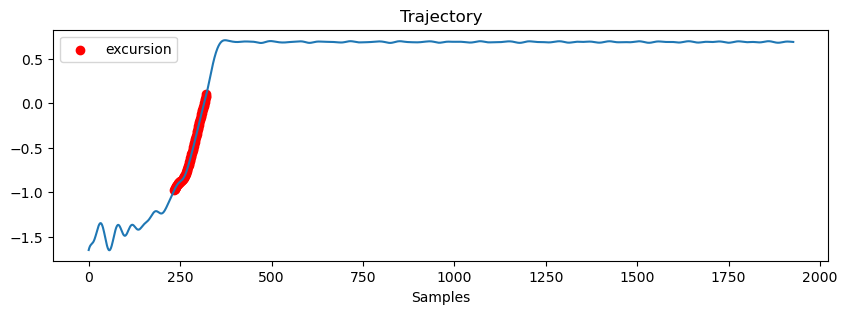

In [8]:

test_data = data[:traj_nsample, past_nsample, 0]
test_time = np.arange(len(test_data))
test_kmeans_idx = kmeans.labels_==dwell_sorted[-1][0] # take id from the last (shortest) cluster
test_kmeans_idx = test_kmeans_idx[:traj_nsample]

plt.figure(figsize=(10,3))
plt.title('Trajectory')
plt.plot(test_time, test_data)
plt.scatter(test_time[test_kmeans_idx], test_data[test_time[test_kmeans_idx]], color='red', label='excursion')
plt.xlabel('Samples')
plt.legend()
plt.show()


### Saving data

In [7]:
datasaved = True
if datasaved:

    lbls = test_data[test_time[test_kmeans_idx]]
    i_lbls = test_time[test_kmeans_idx]

    lbls = np.expand_dims(lbls, 0)
    lbls = np.expand_dims(lbls, -1)
    i_lbls = np.expand_dims(i_lbls, 0)
    i_lbls = np.expand_dims(i_lbls, -1)

    traj  = np.expand_dims(test_data,  0)
    traj  = np.expand_dims(traj, -1)

    step = np.arange(traj.shape[1]).reshape(1, -1, 1)
    savedata = np.concatenate([
        step,
        traj], axis=2)
    util_data.write_datafile(f'{result_dir}/fold_curves_cluster', savedata, delim=' ')

    savedata = np.concatenate([
        i_lbls,
        lbls], axis=2)
    util_data.write_datafile(f'{result_dir}/fold_labels_cluster', savedata, delim=' ')

    print(f'[note]: regime discovery saved')

[note]: regime discovery saved
